# From the raw profiles to the fed-state classification

This walkthrough follows the fed-state analysis of the paper from the raw QIRT-ELISA profiles of 9 rats
to the classification results and figures. Every step runs one of the scripts in this folder and shows
its result next to the files the paper used (`data/`).

The calibration, the feature extraction, the class probabilities, the SHAP values and the figures take
seconds and are run in full. The nested cross-validation of all 81 combinations (30–50 min) and the
permutation test (hours) are shown from their saved results, and one combination and one permutation draw
are rerun to show that they reproduce. The whole notebook runs in about 6 minutes.

Run it from this folder with Jupyter and the packages in `../requirements.txt`. Everything it writes goes to `outputs/`.

In [1]:
import filecmp
import io
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

PILImage.MAX_IMAGE_PIXELS = None  # the 600-dpi figures are larger than PIL's default limit

ROOT = Path.cwd()                 # this folder (fed_state)
DATA = ROOT / "data"
OUT = ROOT / "outputs"
LABELS = {"healthy": "LZ", "pre-diabetic": "OZ", "diabetic": "ZDF"}


def run(script, *args, last=None):
    """Run a script of this folder with this notebook's Python; print its output (or its last lines)."""
    result = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True)
    if result.returncode:
        print(result.stdout, result.stderr)
        raise RuntimeError(f"{script} failed")
    lines = result.stdout.replace(f"{ROOT}/", "").strip().splitlines()   # paths relative to this folder
    print("\n".join(lines[-last:] if last else lines))


def show(*stems, width=1000, gap=24):
    """Display one figure of outputs/figures/, or several side by side at the same height, at the given total width
    and in 256 colours so that the notebook stays small."""
    images = [PILImage.open(OUT / "figures" / f"{stem}.png").convert("RGB") for stem in stems]
    height = round((width - gap * (len(images) - 1)) / sum(image.width / image.height for image in images))
    widths = [round(image.width * height / image.height) for image in images[:-1]]
    widths.append(width - gap * (len(images) - 1) - sum(widths))      # the last figure fills the row exactly
    row = PILImage.new("RGB", (width, height), "white")
    x = 0
    for image, w in zip(images, widths):
        row.paste(image.resize((w, height), PILImage.LANCZOS), (x, 0))
        x += w + gap
    row = row.quantize(colors=256, method=PILImage.Quantize.MEDIANCUT, dither=PILImage.Dither.NONE)
    buffer = io.BytesIO()
    row.save(buffer, format="PNG", optimize=True)
    display(Image(buffer.getvalue()))

## 1. Raw data

`data/raw/fed_state_raw_data.csv` holds, for each rat and 2.5-min time point (0–30 min), the normalized
QIRT-ELISA signal Fi/F0 of insulin, C-peptide and glucagon (F0 is the rat's mean peak area over the
recording). The rat's glucose (mM) and ELISA values (pM) at 0 and 30 min are repeated on every row.

In [2]:
raw = pd.read_csv(DATA / "raw" / "fed_state_raw_data.csv")
print(f"{raw.animal_id.nunique()} rats x {raw.timepoint.nunique()} time points")
raw.assign(phenotype=raw.rat_type.str.lower().map(LABELS)).groupby(["animal_id", "phenotype"]).size().rename(
    "time points").reset_index()

9 rats x 13 time points


,animal_id,phenotype,time points
0,Rat1,LZ,13
1,Rat2,LZ,13
2,Rat3,LZ,13
3,Rat4,OZ,13
4,Rat5,OZ,13
5,Rat6,OZ,13
6,Rat7,ZDF,13
7,Rat8,ZDF,13
8,Rat9,ZDF,13


In [3]:
raw[raw.animal_id == "Rat1"].set_index("timepoint")[["insulin_au", "c_peptide_au", "glucagon_au"]].round(3).T

timepoint,0.0,2.5,5.0,7.5,10.0,12.5,15.0,17.5,20.0,22.5,25.0,27.5,30.0
insulin_au,1.212,0.925,0.738,0.894,1.377,0.745,0.654,1.570,0.751,1.741,0.635,0.587,0.587
c_peptide_au,1.532,0.932,1.645,0.742,0.592,0.981,0.518,0.730,0.799,1.215,1.345,0.969,0.969
glucagon_au,1.216,1.326,0.818,1.104,0.827,1.189,0.630,0.859,0.775,1.557,0.909,0.788,0.788


## 2. Calibration

`src/calibrate.py` maps each profile x onto the rat's own ELISA values e0 and e30 at 0 and 30 min:
slope = (e30 − e0) / (x30 − x0), intercept = e0 − slope · x0, C(t) = slope · x(t) + intercept.

In [4]:
run("src/calibrate.py", last=3)
for name in ("concentration_timeseries.csv", "calibration_parameters.csv"):
    same = filecmp.cmp(OUT / "calibration" / name, DATA / "concentrations" / name, shallow=False)
    print(f"{name}: {'identical to' if same else 'DIFFERENT from'} data/concentrations/")


  Saved: outputs/calibration/concentration_timeseries.csv
  Saved: outputs/calibration/calibration_parameters.csv
concentration_timeseries.csv: identical to data/concentrations/
calibration_parameters.csv: identical to data/concentrations/


In [5]:
parameters = pd.read_csv(OUT / "calibration" / "calibration_parameters.csv")
print(f"signal change between the anchors: {parameters.relative_signal_change.min():.1%} to "
      f"{parameters.relative_signal_change.max():.1%}; flags: {parameters.flag.value_counts().to_dict()}")
parameters.pivot(index="animal_id", columns="hormone", values="slope_pM").round(1)

signal change between the anchors: 8.1% to 73.2%; flags: {'ok': 27}


hormone,c_peptide,glucagon,insulin
animal_id,,,
Rat1,451.7,7.7,40.6
Rat2,1114.8,3.2,97.6
Rat3,390.9,1.6,139.0
Rat4,1995.7,2.4,133.4
Rat5,5508.2,41.0,4846.1
Rat6,6148.7,35.0,6104.1
Rat7,1082.6,4.5,124.0
Rat8,696.9,5.8,180.3
Rat9,288.5,9.7,351.1


## 3. Feature extraction

`src/extract_features.py` computes 189 columns per rat from the concentration profiles
(the feature table of SI Section S9) and keeps 161 of them as the classification matrix.

In [6]:
run("src/extract_features.py", last=5)

Comparison with data/features/:
  fedstate_features_all.csv: identical
  fedstate_X.csv: identical
  fedstate_y.csv: identical
  fedstate_meta.csv: identical


In [7]:
X = pd.read_csv(DATA / "features" / "fedstate_X.csv")
meta = pd.read_csv(DATA / "features" / "fedstate_meta.csv")
print(f"classification matrix: {X.shape[0]} rats x {X.shape[1]} features "
      f"({X.columns[X.nunique() == 1].tolist()} is constant, which leaves 160 candidates)")
X.assign(rat=meta.animal_id, phenotype=meta.rat_type.map(LABELS)).set_index(["rat", "phenotype"])[
    ["glucose_avg_mM", "beta_cell_insulin_cpeptide_correlation", "c_peptide_osc_frequency",
     "c_peptide_osc_signal_entropy"]].round(3)

classification matrix: 9 rats x 161 features (['corr_insulin_glucagon_significant'] is constant, which leaves 160 candidates)


,,glucose_avg_mM,beta_cell_insulin_cpeptide_correlation,c_peptide_osc_frequency,c_peptide_osc_signal_entropy
rat,phenotype,,,,
Rat1,LZ,8.80,-0.032,0.167,0.104
Rat2,LZ,9.05,-0.343,0.100,0.104
Rat3,LZ,8.55,-0.150,0.033,0.119
Rat4,OZ,13.25,0.293,0.267,0.069
Rat5,OZ,10.05,0.460,0.267,0.031
Rat6,OZ,11.70,0.592,0.167,0.024
Rat7,ZDF,33.05,-0.105,0.233,0.142
Rat8,ZDF,32.85,-0.060,0.200,0.131
Rat9,ZDF,17.20,-0.071,0.200,0.219


## 4. Nested cross-validation of 81 combinations

`src/run_classification.py` evaluates every combination of 9 feature selectors and 9 classifiers
by nested leave-one-rat-out cross-validation: each rat is held out once, and the selector, the number of
features (3 or 5) and the classifier are fitted on the other eight. The best combinations of the paper's run:

In [8]:
summary = pd.read_csv(DATA / "classification" / "results_summary.csv")
summary[["selector", "classifier", "macro_f1", "accuracy", "mean_k"]].head(5)

,selector,classifier,macro_f1,accuracy,mean_k
0,mrmr,SVM_linear,0.8857,0.8889,3.89
1,mrmr,LogReg_L2,0.8857,0.8889,3.89
2,mrmr,KNN,0.8857,0.8889,3.89
3,mutual_info,SVM_linear,0.7833,0.7778,4.56
4,mrmr,LDA,0.7746,0.7778,4.11


mRMR with L2 logistic regression (LogReg_L2), linear SVM or KNN classifies 8 of the 9 rats correctly.
The held-out predictions of mRMR + LogReg_L2:

In [9]:
folds = pd.read_csv(DATA / "classification" / "per_fold_details.csv")
lr = folds[(folds.selector == "mrmr") & (folds.classifier == "LogReg_L2")]
lr.assign(true_label=lr.true_label.map(LABELS), pred_label=lr.pred_label.map(LABELS))[
    ["rat_id", "true_label", "pred_label", "correct", "selected_k"]].set_index("rat_id").T

rat_id,Rat1,Rat2,Rat3,Rat4,Rat5,Rat6,Rat7,Rat8,Rat9
true_label,LZ,LZ,LZ,OZ,OZ,OZ,ZDF,ZDF,ZDF
pred_label,LZ,LZ,LZ,LZ,OZ,OZ,ZDF,ZDF,ZDF
correct,True,True,True,False,True,True,True,True,True
selected_k,3,5,5,3,5,5,3,3,3


Rerunning this one combination (about 3 min) gives the same predictions, numbers of features and selected
features in every fold:

In [10]:
check = OUT / "notebook" / "classification"
shutil.rmtree(check, ignore_errors=True)
run("src/run_classification.py", "--selector", "mrmr", "--classifier", "LogReg_L2",
    "--output-dir", str(check), last=8)

BEST: mrmr + LogReg_L2 — Macro-F1 = 0.8857

Comparison with data/classification/, without LogReg_L1:
  results_summary: identical (1 combinations)
  per_fold_details: identical (1 combinations)
  confusion_matrices: identical (1 combinations)
  selected_features: identical (1 combinations)


## 5. Permutation test

`src/run_permutation_test.py` repeats the whole nested cross-validation of mRMR + LogReg_L2 and
mRMR + SVM_linear for 1000 random permutations of the labels. p = (1 + r) / (1 + B), where r is the number of
draws that reach the observed macro-F1 (0.886). From the saved draws:

In [11]:
observed = 0.8857142857142857   # macro-F1 of both recipes with the true labels (8 of 9 rats correct)
for recipe in ("LogReg_L2", "SVM_linear"):
    null = pd.read_csv(DATA / "permutation" / f"per_draw_{recipe}.csv").macro_f1
    r = int((null >= observed - 1e-12).sum())
    print(f"mRMR + {recipe}: null mean {null.mean():.3f}, r = {r} of {len(null)}, p = {(1 + r) / (1 + len(null)):.4f}")

mRMR + LogReg_L2: null mean 0.256, r = 9 of 1000, p = 0.0100
mRMR + SVM_linear: null mean 0.260, r = 8 of 1000, p = 0.0090


Recomputing the true labels and one draw (about 2 min) reproduces the saved values:

In [12]:
check = OUT / "notebook" / "permutation"
shutil.rmtree(check, ignore_errors=True)
run("src/run_permutation_test.py", "--draws", "0", "--workers", "2", "--output-dir", str(check), last=4)

  true labels, mRMR + LogReg_L2: identical (macro-F1 0.886)
  true labels, mRMR + SVM_linear: identical (macro-F1 0.886)
  draw 0, mRMR + LogReg_L2: identical
  draw 0, mRMR + SVM_linear: identical


## 6. Class probabilities and SHAP values

`src/predictive_confidence.py` refits the classifier of each outer fold with the features that
fold selected and records the class probabilities of the held-out rat. `src/shap_values.py`
computes the fold-specific SHAP values of mRMR + LogReg_L2, with the eight training rats as the background.

In [13]:
run("src/predictive_confidence.py", last=1)
run("src/shap_values.py", last=3)

Comparison with data/classification/confidence_by_rat.csv: identical


Comparison with data/shap/:
  shap_values.csv: identical
  shap_base_values.csv: identical


In [14]:
confidence = pd.read_csv(DATA / "classification" / "confidence_by_rat.csv")
confidence.pivot(index="rat_id", columns="classifier", values="max_probability").round(2).T

rat_id,Rat1,Rat2,Rat3,Rat4,Rat5,Rat6,Rat7,Rat8,Rat9
classifier,,,,,,,,,
KNN,0.53,0.89,0.81,1.00,0.74,0.70,0.75,0.91,0.74
LogReg_L2,0.59,0.68,0.90,0.62,0.86,0.80,0.68,0.92,0.94
SVM_linear,0.43,0.47,0.63,0.60,0.50,0.46,0.45,0.57,0.84


## 7. Figures

`figures/fig3.py` and `figures/fig4.py` draw main-text Figs. 3 b–d and 4 d–j, and `figures/si.py` the SI figures, from the files in `data/`. All figures are written to `outputs/figures/`.

In [15]:
for script in ("fig3", "fig4", "si"):
    run(f"figures/{script}.py", last=1)

outputs/figures/fig3_b_to_d.png


outputs/figures/fig4_j.pdf


outputs/figures/si_rat4_shap.pdf


**Fig. 3 b–d:** glucose and the calibrated insulin, C-peptide and glucagon profiles of the LZ, OZ and ZDF rats (mean ± SD), with the ELISA values at 0 and 30 min (open circles).

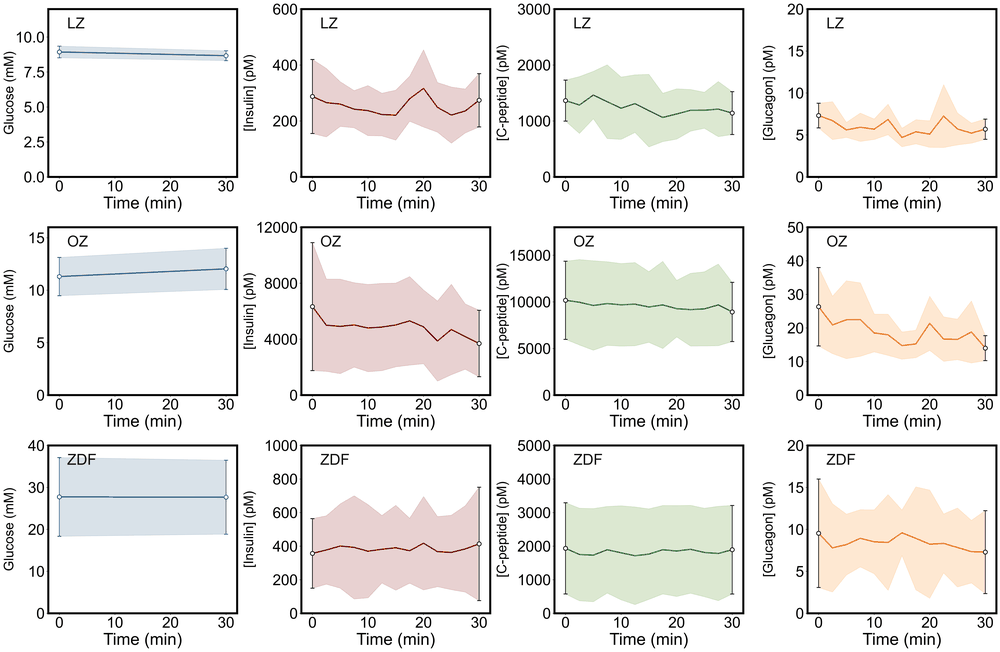

In [16]:
show("fig3_b_to_d")

**Fig. 4 d–g:** macro-F1 of the 81 combinations, predictive confidence, permutation test, confusion matrix.

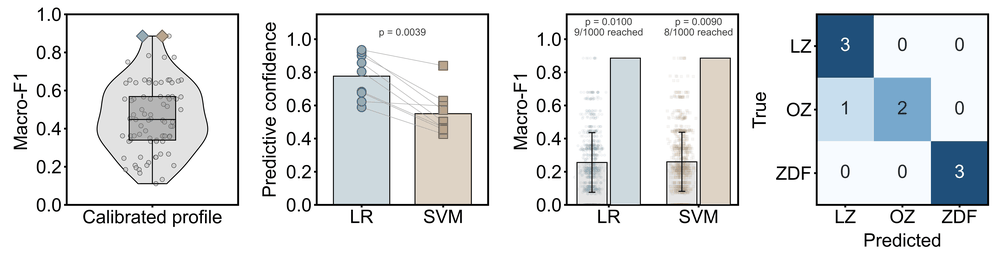

In [17]:
show("fig4_d_to_g")

**Fig. 4 h–i:** how often each feature was selected, and the z-scores and Hedges' g of six of them.

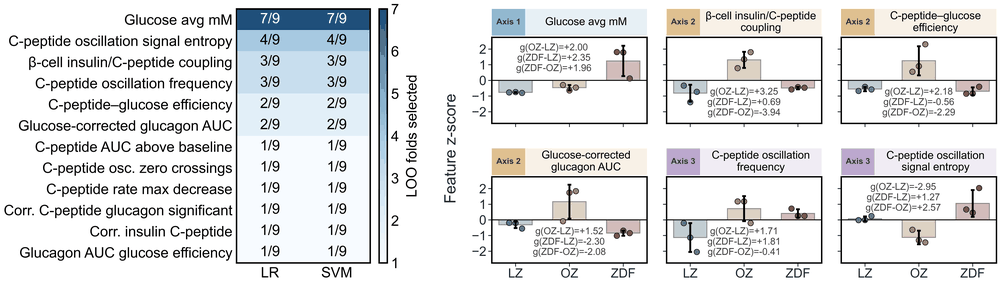

In [18]:
show("fig4_h_i")

**Fig. 4 j:** SHAP waterfalls of the nine held-out rats.

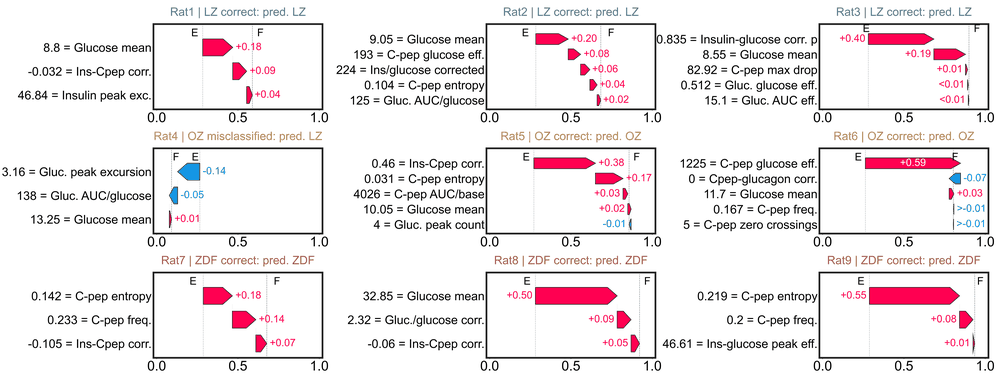

In [19]:
show("fig4_j")

## 8. Supplementary figures

Normalized device profile (Fi/F0, left axis) and ELISA values at 0 and 30 min (pM, right axis) of each rat, with the phenotype means.

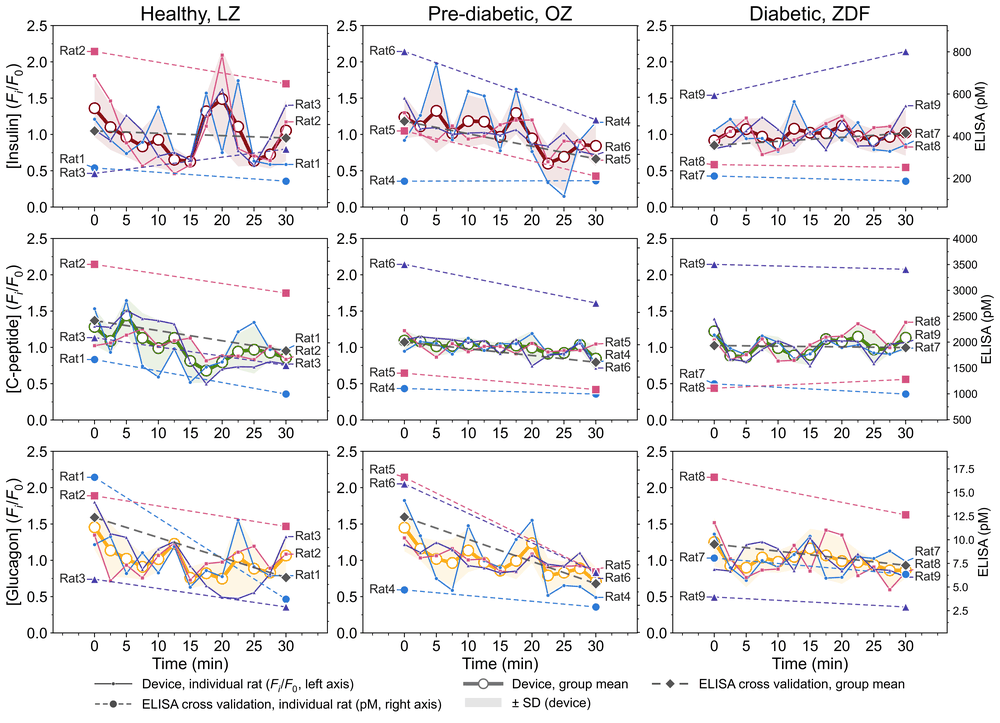

In [20]:
show("si_normalized_profiles")

Glucose and the calibrated profiles of each rat, with the ELISA values at 0 and 30 min.

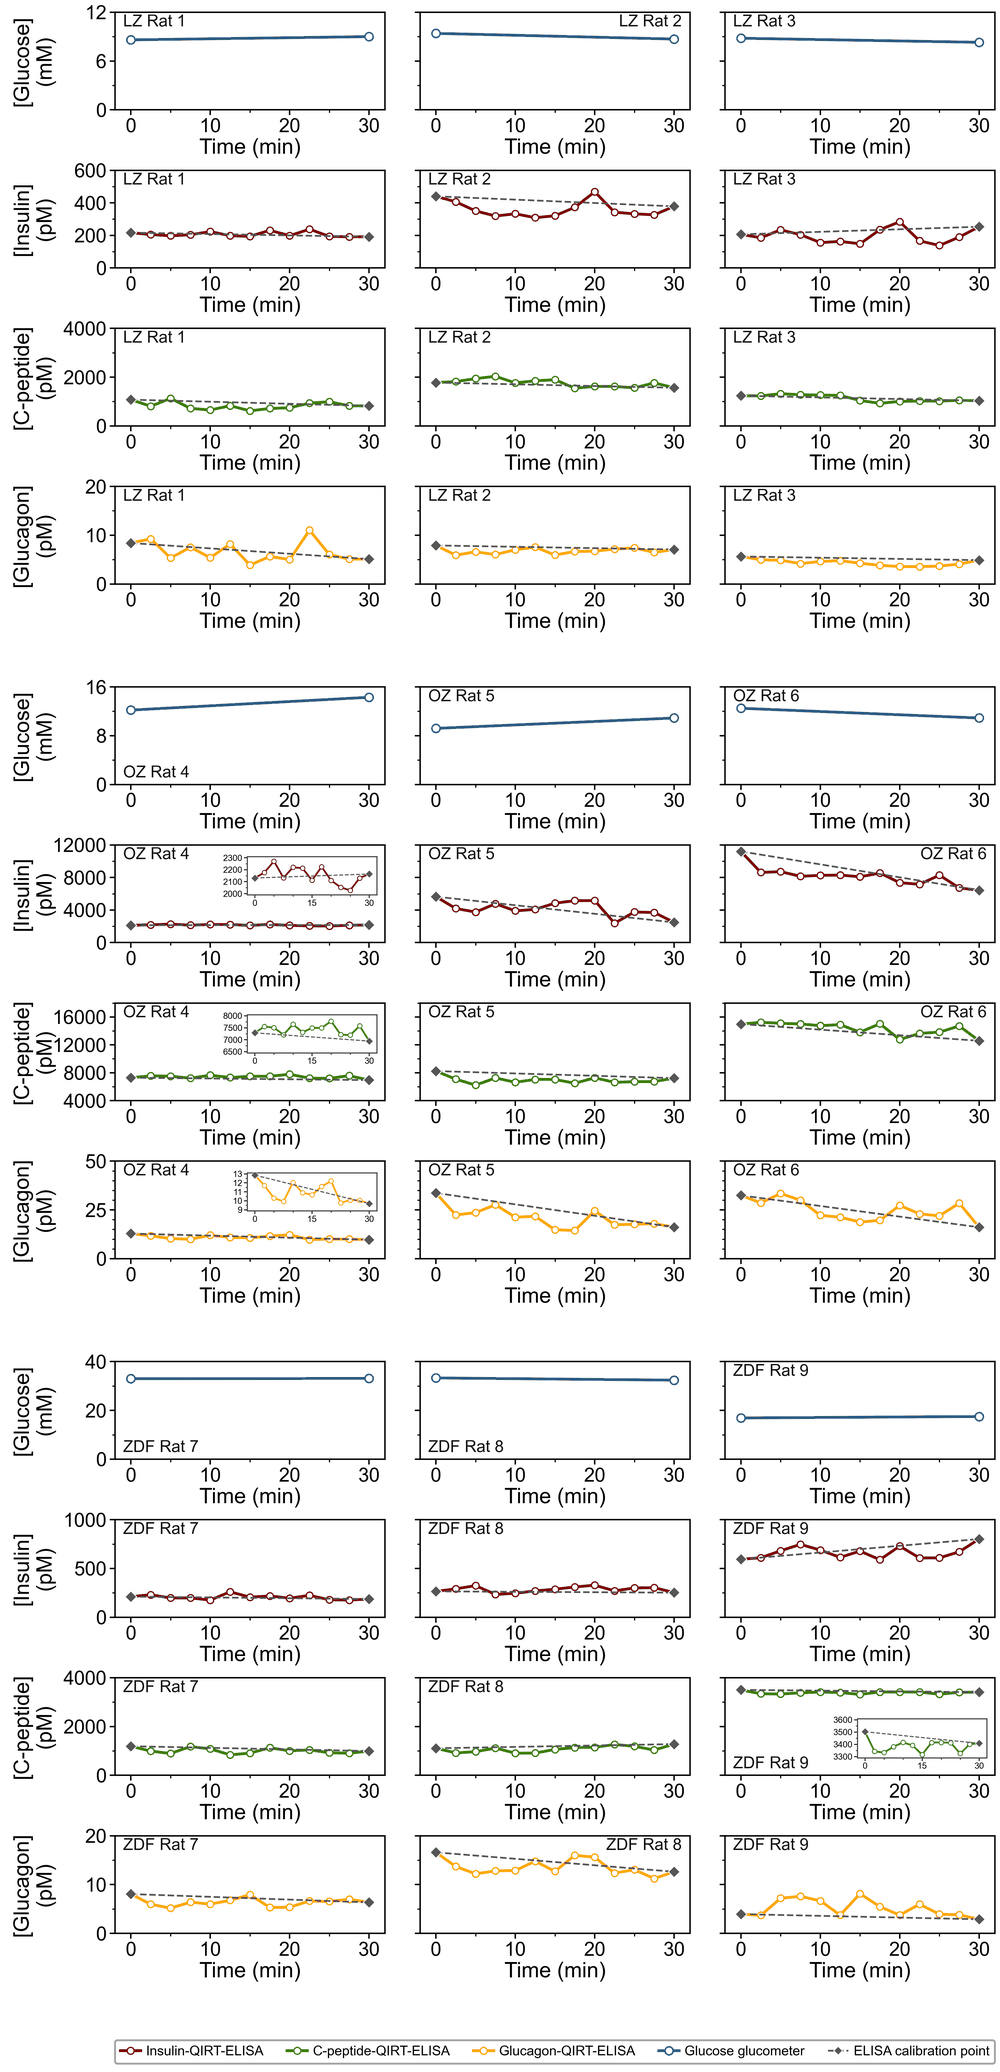

In [21]:
show("si_individual_profiles")

Macro-F1 of the 81 combinations.

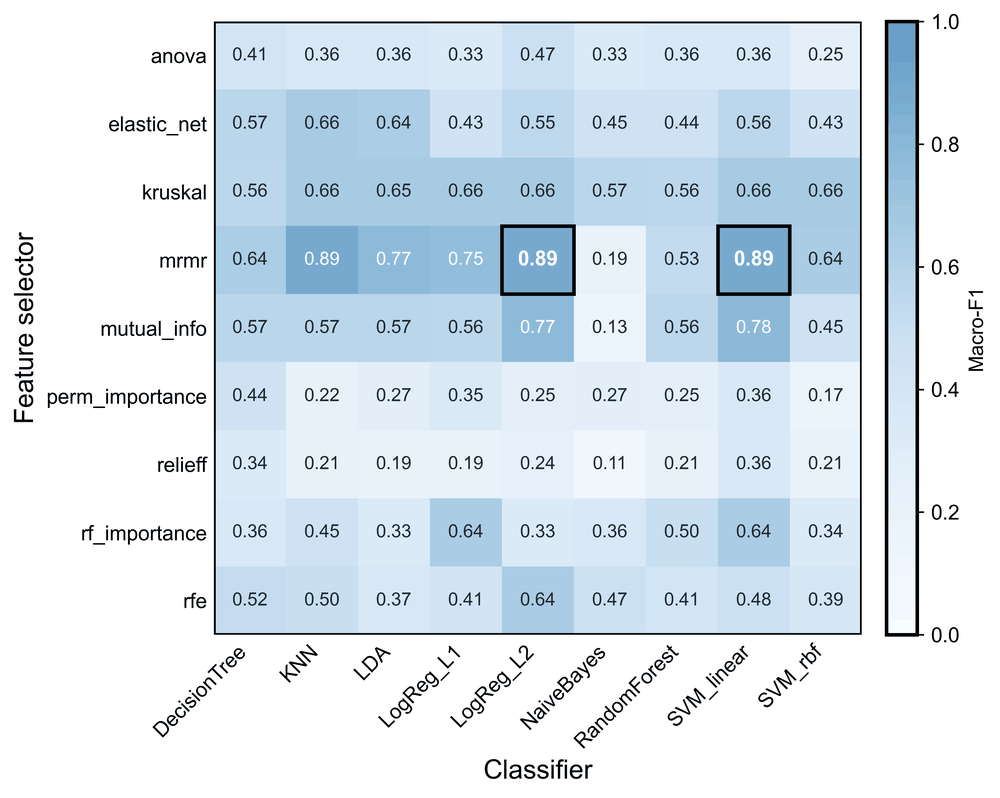

In [22]:
show("si_macro_f1_heatmap")

Label-permutation test of mRMR + LogReg_L2 and mRMR + SVM_linear: the null distribution of macro-F1 and its cumulative distribution.

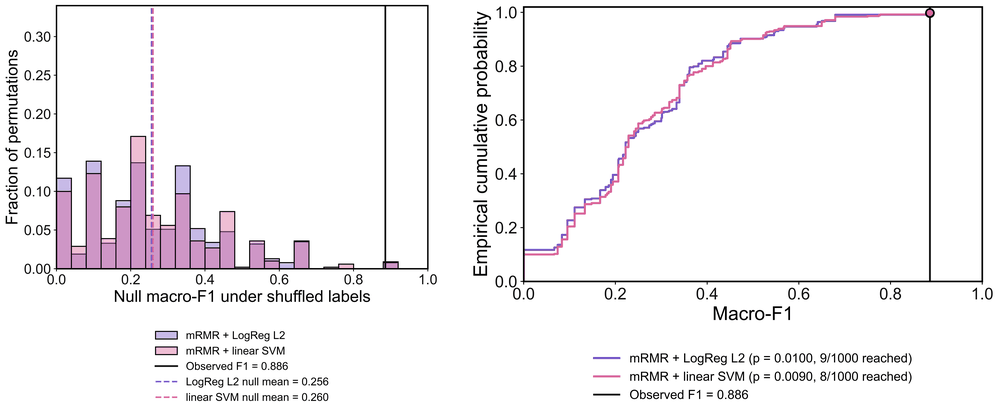

In [23]:
show("si_permutation_null", "si_permutation_ecdf")

SHAP attributions of Rat4, the misclassified OZ rat, to its true class (OZ) and its predicted class (LZ).

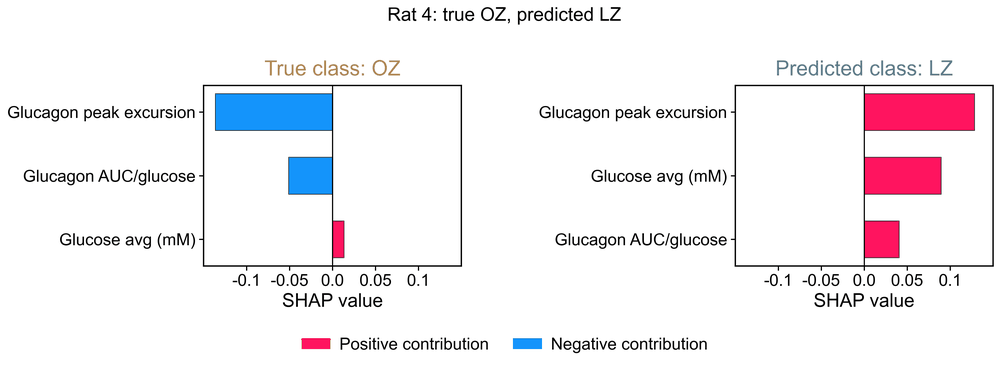

In [24]:
show("si_rat4_shap")